# Puente Z24: estructura de los datos disponibles

Este notebook describe la información que hay en la carpeta `datos/` del puente Z24: qué archivos hay, cómo están organizados, qué mide cada canal y en qué formato está. No analiza los datos. Solo carga un ejemplo de cada tipo para ver qué contienen.

Todo se lee directamente de los ZIP, sin descomprimirlos en disco. La única excepción es un inventario de las mediciones horarias, que se guarda en `cache/` la primera vez (tarda alrededor de 1 minuto).

**Fuentes.** Lo que se dice sobre el puente y los sensores viene de la documentación incluida en `datos/` (apéndices del informe EMPA 168'349/20e). Lo que se dice sobre los archivos se obtiene leyendo los propios archivos. Cuando algo viene de otra fuente (literatura del Z24), se indica.

**Índice**

1. [El puente Z24 y sus dos campañas](#sec1)
2. [Contenido de la carpeta `datos/`](#sec2)
3. [Monitoreo continuo (EMS)](#sec3)
   - 3.1 [Organización de los archivos](#sec3-1)
   - 3.2 [Acelerómetros](#sec3-2)
   - 3.3 [Archivos de aceleración (`.aaa`)](#sec3-3)
   - 3.4 [Registro de vehículos (`car.aaa`)](#sec3-4)
   - 3.5 [Variables ambientales (`.env`)](#sec3-5)
   - 3.6 [Cobertura en el tiempo](#sec3-6)
4. [Ensayos de daño progresivo (PDT)](#sec4)
   - 4.1 [Organización de los archivos](#sec4-1)
   - 4.2 [Escenarios de daño](#sec4-2)
   - 4.3 [Setups, malla de medición y canales](#sec4-3)
   - 4.4 [Archivos `.mat` y ejemplo](#sec4-4)
   - 4.5 [Inventario completo](#sec4-5)
5. [Resumen: con qué información contamos](#sec5)

### Glosario

**Campañas y ensayos**
- **EMS** (*Environmental Monitoring System*): sistema de monitoreo continuo del Z24. Midió cada hora aceleraciones y variables ambientales durante unos 10 meses.
- **PDT** (*Progressive Damage Tests*): ensayos de daño progresivo. Se introdujeron 17 escenarios de daño, uno tras otro, y después de cada uno se midió la vibración del puente.
- **AVT** (*Ambient Vibration Test*): ensayo de vibración ambiental. Se mide la respuesta del puente bajo excitación no controlada (viento, tráfico de la autopista de abajo).
- **FVT** (*Forced Vibration Test*): ensayo de vibración forzada. Se excita el puente con excitadores (*shakers*) y se mide la fuerza aplicada y la respuesta.
- **Setup**: una configuración de sensores. Como no hay acelerómetros para cubrir toda la malla a la vez, se mueven por tramos: 9 setups por ensayo.
- **Canal de referencia** (R1, R2, R3): sensores que no se mueven entre setups. Permiten unir los 9 setups en una sola forma modal.
- **DP** (*Driving Point*): punto donde actúa un excitador en el FVT. Los canales `DP1V` y `DP2V` son las señales de fuerza de los dos excitadores.
- **SIMCES** (*System Identification to Monitor Civil Engineering Structures*): proyecto europeo (BRITE-EuRam BE96-3157) dentro del cual se hicieron el EMS y los PDT.
- **EMPA**: laboratorio federal suizo de ensayo de materiales que hizo las mediciones.

**Señales**
- **Frecuencia de muestreo** ($f_s$): muestras por segundo. Aquí $f_s = 100$ Hz, es decir, un intervalo $\Delta t = 0.01$ s.
- **PSD** (*Power Spectral Density*): densidad espectral de potencia. Indica cuánta energía tiene la señal en cada frecuencia; los modos del puente aparecen como picos.
- **Método de Welch**: estima la PSD promediando los espectros de varios segmentos de la señal.
- **Promedios (*averages*)**: cada registro de 65 536 muestras se adquirió en 8 segmentos de 8192 muestras, que pueden estar separados por pausas.

**Archivos**
- **`.aaa`**: archivo de texto con una serie de tiempo de un canal.
- **`.env`**: archivo de texto con 10 lecturas de las variables ambientales.
- **`.mat`**: archivo de MATLAB. En los PDT contiene la matriz `data` (una columna por canal) y `labelshulp` (nombre de cada canal).
- **PRE / POS**: lecturas ambientales tomadas antes (*prior*) y después (*post*) de las aceleraciones de cada hora.
- **Valor centinela**: número fijo que el registrador escribe cuando un sensor no da lectura (aquí 3276.7, −242.7 o −244.3). Hay que tratarlo como dato faltante.

**Direcciones de medición**
- **L, T, V**: longitudinal, transversal y vertical. En el tablero, L apunta hacia Koppigen, V hacia arriba y T hacia Berna. En las pilas los sensores están girados (ver [4.3](#sec4-3)).

In [1]:
import io
import re
import zipfile
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
from IPython.display import Markdown, display
from scipy import signal

DATA_DIR = Path("datos")
CACHE_DIR = Path("cache")
EMS_ARCHIVES = ["Z24ems1.zip", "Z24ems2.zip", "Z24ems3.zip"]
PDT_ARCHIVES = ["pdt_01-08.zip", "pdt_09_17.zip"]
FS = 100.0                 # sampling frequency of every record (Hz)
SENTINEL_ABS = 100.0       # env values with |x| >= this are logger error codes (3276.7, -242.7, -244.3)
FIRST_LOWERING = pd.Timestamp("1998-08-11 13:15")  # first pier lowering (Table 8, Appendix F of C11)

# To number the tables and figures automatically
t_num = 0
f_num = 0

# Function to display a DataFrame as a table with a caption and optional formatting
def show_table(df, number, caption, precision=2, hide_index=False, n_rows=None):
    display(Markdown(f"**Tabla {number}.** {caption}"))

    # Truncate table (for long DataFrames)
    if n_rows is not None and len(df) > 2 * n_rows:
        ellipsis_row = pd.DataFrame([["..."] * df.shape[1]], columns=df.columns, index=["..."])
        df = pd.concat([df.head(n_rows), ellipsis_row, df.tail(n_rows)])

    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)

# Function to display a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))


def psd(x, nperseg=4096):
    # Welch power spectral density of a signal without its mean
    x = np.asarray(x, float)
    return signal.welch(x - x.mean(), fs=FS, nperseg=nperseg)


# ---------- Readers ----------
def read_aaa(raw):
    # .aaa: label, declared number of samples, sample interval, samples, optional text footer
    tokens = raw.decode("latin-1").split()
    label, n_declared, dt = tokens[0], int(tokens[1]), float(tokens[2])
    values = []
    for tok in tokens[3:3 + n_declared]:
        try:
            values.append(float(tok))
        except ValueError:   # the footer starts before n_declared values were read
            break
    return label, n_declared, dt, np.array(values)


def read_env(raw):
    # .env: header with "LABEL [unit]" pairs, 10 numeric rows (scans), then a text footer
    lines = raw.decode("latin-1").splitlines()
    labels = [lab for lab, _ in re.findall(r"(\S+)\s*\[([^\]]*)\]", lines[0])]
    rows = [ln.split() for ln in lines[1:]]
    n_cols = max(len(r) for r in rows[:5])
    values = np.array([r for r in rows if len(r) == n_cols], float)
    # Header has fewer labels than columns and repeats some names: make them unique
    names, seen = [], {}
    for j in range(n_cols):
        base = labels[j] if j < len(labels) else f"col{j}"
        seen[base] = seen.get(base, 0) + 1
        names.append(base if seen[base] == 1 else f"{base}_{seen[base]}")
    started = re.search(r"started\s*:\s*(.+)", "\n".join(lines))
    start = pd.to_datetime(started.group(1).strip(), format="%a %b %d %H:%M:%S %Y") if started else pd.NaT
    return pd.DataFrame(values, columns=names), start


def open_ems_hour(code):
    # Return the inner ZipFile of one hourly measurement, e.g. code = "01C14"
    for archive in EMS_ARCHIVES:
        outer = zipfile.ZipFile(DATA_DIR / archive)
        if f"{code}.zip" in outer.namelist():
            return zipfile.ZipFile(io.BytesIO(outer.read(f"{code}.zip")))
    raise KeyError(code)


def load_ems_hour(code):
    # Accelerations (DataFrame, one column per channel) and the PRE environmental scans
    inner = open_ems_hour(code)
    acc = {}
    for name in sorted(inner.namelist()):
        suffix = name[5:-4]
        if name.lower().endswith(".aaa") and suffix.isdigit():
            acc[suffix] = read_aaa(inner.read(name))[3]
    n = min(len(x) for x in acc.values())
    acc = pd.DataFrame({ch: x[:n] for ch, x in acc.items()})
    pre = [n for n in inner.namelist() if n.upper().endswith("PRE.ENV")]
    env = read_env(inner.read(pre[0]))[0] if pre else None
    return acc, env


def pdt_index():
    # One row per .mat file of the PDT archives (scenario 08 is stored as nested zips)
    rows = []
    for archive in PDT_ARCHIVES:
        zf = zipfile.ZipFile(DATA_DIR / archive)
        for name in zf.namelist():
            if name.lower().endswith(".mat"):
                parts = name.split("/")
                rows.append(dict(archive=archive, inner_zip=None, path=name, scenario=int(parts[0]),
                                 test=parts[1].upper(), setup=int(parts[-1][-6:-4])))
            elif name.lower().endswith(".zip"):
                inner = zipfile.ZipFile(io.BytesIO(zf.read(name)))
                for sub in inner.namelist():
                    if sub.lower().endswith(".mat"):
                        rows.append(dict(archive=archive, inner_zip=name, path=sub, scenario=int(name[:2]),
                                         test=sub.split("/")[0].upper(), setup=int(sub[-6:-4])))
    index = pd.DataFrame(rows)
    # Scenario 08 is stored twice (folders and nested zips, identical files): keep the folder copy
    index["nested"] = index["inner_zip"].notna()
    index = index.sort_values(["scenario", "test", "setup", "nested"]).drop_duplicates(["scenario", "test", "setup"])
    return index.drop(columns="nested").reset_index(drop=True)


def read_pdt_bytes(row):
    zf = zipfile.ZipFile(DATA_DIR / row.archive)
    if not isinstance(row.inner_zip, str):   # plain .mat (not inside a nested zip)
        return zf.read(row.path)
    return zipfile.ZipFile(io.BytesIO(zf.read(row.inner_zip))).read(row.path)


def load_pdt(scenario, test, setup, index):
    # Data matrix (samples x channels) and channel labels of one PDT setup
    row = index.query("scenario == @scenario and test == @test and setup == @setup").iloc[0]
    mat = sio.loadmat(io.BytesIO(read_pdt_bytes(row)))
    labels = [str(lab).strip() for lab in mat["labelshulp"]]
    return pd.DataFrame(mat["data"], columns=labels)

---
<a id="sec1"></a>
## 1. El puente Z24 y sus dos campañas

**El puente** (Apéndices B y C de `C11-Appendices.pdf`):
- Puente carretero de hormigón pretensado, con sección cajón de dos celdas, en el cantón de Berna (Suiza). Unía Utzenstorf y Koppigen y cruzaba la autopista A1 Berna–Zúrich.
- Tres vanos de 14 + 30 + 14 m, más dos voladizos de 2.70 m en los extremos. Ancho del tablero: 8.60 m. Canto del cajón: 1.10 m.
- Se apoyaba en dos pilas intermedias (pila Utzenstorf y pila Koppigen) y, en cada extremo, en columnas junto al estribo (Fig. 27).
- Fue demolido a fines de 1998 (literatura). Antes de demolerlo, el laboratorio EMPA hizo dos campañas de medición dentro del proyecto SIMCES.

**Las dos campañas:**

| | EMS (monitoreo continuo) | PDT (daño progresivo) |
|---|---|---|
| Objetivo | Ver cómo el ambiente (sobre todo la temperatura) cambia las propiedades dinámicas | Ver cómo el daño cambia las propiedades dinámicas |
| Periodo | 10.11.1997 – 10.09.1998, cada hora | Agosto – septiembre de 1998, después de cada escenario de daño |
| Aceleración | 8 acelerómetros fijos | Malla de 151 puntos (tablero y pilas), unos 290 canales repartidos en 9 setups, AVT y FVT |
| Ambiente | 53 columnas (temperaturas, humedad, viento, etc.) | — |
| Formato | Texto (`.aaa`, `.env`) dentro de ZIP horarios | MATLAB (`.mat`) |

El último mes del EMS se solapa con los PDT: el primer descenso de pila fue el 11.08.1998 a las 13:15 (Tabla 8 del Apéndice F). Por eso el EMS incluye horas con el puente sano y horas con el puente dañado.

---
<a id="sec2"></a>
## 2. Contenido de la carpeta `datos/`

La carpeta tiene 8 archivos y ocupa unos 10 GB. Los datos están en 5 ZIP, que no se descomprimen.

In [2]:
descriptions = {
    "Z24ems1.zip": "EMS, mediciones horarias (parte 1 de 3; fechas en la Tabla 2)",
    "Z24ems2.zip": "EMS, mediciones horarias (parte 2 de 3)",
    "Z24ems3.zip": "EMS, mediciones horarias (parte 3 de 3)",
    "pdt_01-08.zip": "PDT, escenarios 01 a 08 (AVT y FVT)",
    "pdt_09_17.zip": "PDT, escenarios 09 a 17 (AVT y FVT)",
    "Z24-EMS-readme.pdf": "Apéndices H, I y J: sensores del EMS y formato de sus archivos",
    "C11-Appendices.pdf": "Apéndices A–N del informe EMPA 168'349/20e (puente, malla PDT, formatos)",
    "readme.txt": "Nota sobre el formato .mat de los PDT",
}
files = pd.DataFrame([
    {"Archivo": p.name, "Tamaño (MB)": p.stat().st_size / 1e6,
     "Archivos dentro": len(zipfile.ZipFile(p).namelist()) if p.suffix == ".zip" else None,
     "Contenido": descriptions.get(p.name, "")}
    for p in sorted(DATA_DIR.iterdir())
])

t_num += 1
show_table(files, t_num, "Archivos de la carpeta `datos/`.", precision=0, hide_index=True)
print(f"Total: {files['Tamaño (MB)'].sum() / 1e3:.1f} GB")

**Tabla 1.** Archivos de la carpeta `datos/`.

Archivo,Tamaño (MB),Archivos dentro,Contenido
C11-Appendices.pdf,79,nan,"Apéndices A–N del informe EMPA 168'349/20e (puente, malla PDT, formatos)"
pdt_01-08.zip,2027,483,"PDT, escenarios 01 a 08 (AVT y FVT)"
pdt_09_17.zip,2102,824,"PDT, escenarios 09 a 17 (AVT y FVT)"
readme.txt,0,nan,Nota sobre el formato .mat de los PDT
Z24-EMS-readme.pdf,4,nan,"Apéndices H, I y J: sensores del EMS y formato de sus archivos"
Z24ems1.zip,2072,1817,"EMS, mediciones horarias (parte 1 de 3; fechas en la Tabla 2)"
Z24ems2.zip,2065,1820,"EMS, mediciones horarias (parte 2 de 3)"
Z24ems3.zip,2287,2016,"EMS, mediciones horarias (parte 3 de 3)"


Total: 10.6 GB


**Documentación incluida:**
- `Z24-EMS-readme.pdf` (10 páginas): ubicación de los acelerómetros del EMS (Fig. 37), ubicación de los sensores de temperatura (Figs. 38–41), significado de cada variable ambiental (Tabla 11), nombres de archivo (Apéndice I) y formato de los archivos (Apéndice J).
- `C11-Appendices.pdf` (39 páginas, escaneado): incluye lo anterior y además la geometría del puente (Apéndice C), el sistema para bajar la pila (Apéndice D), las deflexiones medidas durante el descenso de la pila (Apéndice F), la organización de los datos PDT (Apéndice K) y la malla de medición de los PDT (Apéndice L).
- `readme.txt`: los `.mat` de los PDT contienen `data` y `labelshulp`, siempre a 100 Hz.
- Dentro de los ZIP de los PDT hay además un informe `.DOC` por ensayo (ver [4.1](#sec4-1)).

---
<a id="sec3"></a>
## 3. Monitoreo continuo (EMS)

<a id="sec3-1"></a>
### 3.1 Organización de los archivos

Cada medición horaria es un ZIP dentro de uno de los tres `Z24emsN.zip`:

```
Z24ems1.zip
├── 01C14.zip            ← una hora: semana 01, día C, hora 14
│   ├── 01C1403.aaa      ← aceleración, canal 03
│   ├── 01C1405.aaa      ← ... canales 05, 06, 07, 10, 12, 14, 16
│   ├── 01C14car.aaa     ← registro de vehículos (no documentado)
│   ├── 01C14PRE.env     ← ambientales antes de las aceleraciones
│   └── 01C14POS.env     ← ambientales después de las aceleraciones
├── 01C15.zip
└── ...
```

**Nombre de archivo** `WWDHH` (Apéndice I.1):
- `WW`: semana de funcionamiento del EMS, desde 01.
- `D`: día de la semana, de A a G.
- `HH`: hora del día, de 00 a 23.

Cada hora empieza con una lectura ambiental (PRE), sigue con las aceleraciones y termina con otra lectura ambiental (POS).

La fecha y hora exactas se leen del pie del archivo `PRE.env` (línea `EnvScan started`). La celda siguiente recorre las 5653 horas y guarda un inventario en `cache/ems_inventory.csv` con:
- los canales presentes y la fecha de cada hora;
- la media y la desviación estándar de los primeros 27 s de cada canal de aceleración, para detectar canales muertos;
- el promedio de cada variable ambiental (lectura PRE).

La primera vez tarda unos 2 minutos; después se lee del archivo.

In [3]:
def build_ems_inventory():
    rows = []
    for archive in EMS_ARCHIVES:
        outer = zipfile.ZipFile(DATA_DIR / archive)
        for info in outer.infolist():
            code = info.filename[:5]
            with outer.open(info) as f:
                inner = zipfile.ZipFile(f)
                names = inner.namelist()
                suffixes = [n[5:-4] for n in names]
                row = dict(archive=archive, code=code, n_files=len(names),
                           channels=" ".join(sorted(s for s in suffixes if s.isdigit())),
                           has_car="car" in suffixes,
                           has_pre=any(s.upper() == "PRE" for s in suffixes),
                           has_pos=any(s.upper() == "POS" for s in suffixes))
                # Quick check of each acceleration channel: first ~27 s only (first 40 kB of text)
                for name in names:
                    suffix = name[5:-4]
                    if name.lower().endswith(".aaa") and suffix.isdigit():
                        with inner.open(name) as g:
                            head = np.array(g.read(40000).decode("latin-1").split()[3:-1], float)
                        row[f"std_{suffix}"], row[f"mean_{suffix}"] = head.std(), head.mean()
                if row["has_pre"]:
                    env, start = read_env(inner.read([n for n in names if n.upper().endswith("PRE.ENV")][0]))
                    row["start"] = start
                    row.update(env.mean().to_dict())
                else:
                    # No PRE file: use the time stamp of the first acceleration file
                    row["start"] = pd.Timestamp(*inner.infolist()[0].date_time)
                rows.append(row)
    return pd.DataFrame(rows)


inventory_path = CACHE_DIR / "ems_inventory.csv"
if inventory_path.exists():
    ems = pd.read_csv(inventory_path, parse_dates=["start"], dtype={"code": str, "channels": str})
else:
    CACHE_DIR.mkdir(exist_ok=True)
    ems = build_ems_inventory()
    ems.to_csv(inventory_path, index=False)
ems = ems.sort_values("start").reset_index(drop=True)

summary = ems.groupby("archive", sort=False).agg(
    **{"Horas": ("code", "size"), "Primera": ("start", "min"), "Última": ("start", "max"),
       "Primer código": ("code", "first"), "Último código": ("code", "last")})
summary.loc["Total"] = [len(ems), ems["start"].min(), ems["start"].max(), ems["code"].iloc[0], ems["code"].iloc[-1]]
summary.index.name = "Archivo"

t_num += 1
show_table(summary, t_num, "Mediciones horarias del EMS en cada archivo.")

**Tabla 2.** Mediciones horarias del EMS en cada archivo.

,Horas,Primera,Última,Primer código,Último código
Archivo,,,,,
Z24ems1.zip,1817,1997-11-10 14:00:13,1998-01-27 23:00:10,01C14,12D23
Z24ems2.zip,1820,1998-01-28 00:00:10,1998-04-22 23:00:10,12E00,24E23
Z24ems3.zip,2016,1998-04-23 00:00:10,1998-09-10 13:00:10,24F00,44F13
Total,5653,1997-11-10 14:00:13,1998-09-10 13:00:10,01C14,44F13


La letra del día se puede comprobar con las fechas leídas: la Tabla 3 muestra, para cada letra, el día de la semana en que cae.

In [4]:
day_names = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
weekday = (ems.assign(Letra=ems["code"].str[2], day=ems["start"].dt.day_of_week.map(dict(enumerate(day_names))))
              .groupby("Letra")["day"].agg(lambda s: s.value_counts().index[0]))
hour_ok = (ems["code"].str[3:5].astype(int) == ems["start"].dt.hour)

t_num += 1
show_table(weekday.to_frame("Día de la semana").T, t_num, "Día de la semana de cada letra `D` del nombre `WWDHH`.")
print(f"The hour HH of the name matches the time stamp in {hour_ok.mean():.1%} of the files "
      f"({(~hour_ok).sum()} files do not match)")

**Tabla 3.** Día de la semana de cada letra `D` del nombre `WWDHH`.

Letra,A,B,C,D,E,F,G
Día de la semana,sábado,domingo,lunes,martes,miércoles,jueves,viernes


The hour HH of the name matches the time stamp in 99.9% of the files (5 files do not match)


- La semana del EMS empieza el sábado (A = sábado, ..., G = viernes).
- La hora del nombre coincide con la hora leída en casi todos los archivos. Aun así, para ordenar las mediciones conviene usar la fecha leída (`start`) y no el nombre.

<a id="sec3-2"></a>
### 3.2 Acelerómetros

El EMS se instaló con 16 acelerómetros (Kinemetrics FBA 11), pero 8 fallaron durante la campaña y sus datos no se distribuyeron (Fig. 37 de `Z24-EMS-readme.pdf`). Quedan 8 canales. La Tabla 4 resume dónde están, según la Fig. 37. Las posiciones son aproximadas; para ubicarlos con precisión hay que ver esa figura.

In [5]:
ems_sensors = pd.DataFrame([
    ("03", "Pila (fuste, el más alto de 3 sensores)", "Longitudinal (L)"),
    ("05", "Tablero, borde norte, lado Utzenstorf", "Vertical (V)"),
    ("06", "Tablero, interior, lado Utzenstorf", "Longitudinal (L)"),
    ("07", "Tablero, borde norte, lado Koppigen", "Vertical (V)"),
    ("10", "Tablero, borde norte, lado Utzenstorf", "Vertical (V)"),
    ("12", "Tablero, borde norte, lado Koppigen", "Vertical (V)"),
    ("14", "Tablero, interior, extremo Koppigen", "Transversal (T)"),
    ("16", "Tablero, interior, lado Utzenstorf", "Transversal (T)"),
], columns=["Canal", "Ubicación (Fig. 37)", "Dirección"])
failed = "01, 02, 04, 08, 09, 11, 13, 15"

channel_sets = ems["channels"].value_counts().rename_axis("Canales presentes").reset_index(name="Horas")

t_num += 1
show_table(ems_sensors, t_num, "Acelerómetros del EMS con datos disponibles.", hide_index=True)
print(f"Failed sensors (no data): {failed}")
t_num += 1
show_table(channel_sets, t_num, "Combinaciones de canales encontradas en las 5653 horas.", hide_index=True)

**Tabla 4.** Acelerómetros del EMS con datos disponibles.

Canal,Ubicación (Fig. 37),Dirección
03,"Pila (fuste, el más alto de 3 sensores)",Longitudinal (L)
05,"Tablero, borde norte, lado Utzenstorf",Vertical (V)
06,"Tablero, interior, lado Utzenstorf",Longitudinal (L)
07,"Tablero, borde norte, lado Koppigen",Vertical (V)
10,"Tablero, borde norte, lado Utzenstorf",Vertical (V)
12,"Tablero, borde norte, lado Koppigen",Vertical (V)
14,"Tablero, interior, extremo Koppigen",Transversal (T)
16,"Tablero, interior, lado Utzenstorf",Transversal (T)


Failed sensors (no data): 01, 02, 04, 08, 09, 11, 13, 15


**Tabla 5.** Combinaciones de canales encontradas en las 5653 horas.

Canales presentes,Horas
03 05 06 07 10 12 14 16,5652
03 05 06,1


- Casi todas las horas tienen los 8 canales. Una sola hora tiene solo 3.
- Los sensores que fallaron estaban en el borde sur (11, 13, 15), en el borde norte hacia el centro del puente (08, 09), en el extremo Utzenstorf (04) y en la parte baja de la pila (01, 02).
- Sin ellos no quedan sensores verticales en el borde sur ni cerca del centro del vano central. Eso dificulta separar flexión de torsión y reconstruir formas modales con el EMS. Para formas modales completas están los PDT.

Que un canal esté presente no significa que funcione. La Tabla 6 cuenta las horas en que cada canal es una línea plana (desviación estándar nula en los primeros 27 s), es decir, un sensor muerto o saturado.

In [6]:
ems_channels = ["03", "05", "06", "07", "10", "12", "14", "16"]
flat = pd.DataFrame({ch: ems[f"std_{ch}"] < 1e-9 for ch in ems_channels})
flat_summary = pd.DataFrame({
    "Horas planas": flat.sum(),
    "% de las horas": 100 * flat.mean(),
    "Valor constante": [", ".join(f"{v:.4f}" for v in np.unique(ems.loc[flat[ch], f"mean_{ch}"].round(4))[:4])
                        for ch in ems_channels],
})
flat_summary.index.name = "Canal"
t_num += 1
show_table(flat_summary, t_num, "Horas en que cada canal de aceleración del EMS es una línea plana (primeros 27 s).", precision=1)

ch10 = flat["10"].groupby(ems["start"].dt.to_period("M")).mean().mul(100).round(0)
print("Channel 10 flat (% of hours) per month:", ch10.to_dict())

**Tabla 6.** Horas en que cada canal de aceleración del EMS es una línea plana (primeros 27 s).

,Horas planas,% de las horas,Valor constante
Canal,,,
03,188,3.3,"-0.0109, -0.0055, -0.0035, -0.0017"
05,0,0.0,
06,0,0.0,
07,0,0.0,
10,3401,60.2,-10.9177
12,0,0.0,
14,0,0.0,
16,0,0.0,


Channel 10 flat (% of hours) per month: {Period('1997-11', 'M'): 0.0, Period('1997-12', 'M'): 63.0, Period('1998-01', 'M'): 99.0, Period('1998-02', 'M'): 100.0, Period('1998-03', 'M'): 97.0, Period('1998-04', 'M'): 94.0, Period('1998-05', 'M'): 0.0, Period('1998-06', 'M'): 19.0, Period('1998-07', 'M'): 14.0, Period('1998-08', 'M'): 40.0, Period('1998-09', 'M'): 45.0}


- **El canal 10 está muerto en el 60 % de las horas**: queda fijo en −10.92 casi todo el periodo de diciembre de 1997 a abril de 1998, y a ratos después. Cualquier análisis que lo use tiene que filtrar esas horas.
- El canal 03 queda plano en un 3 % de las horas, en valores que coinciden con los límites del rango de medición (±0.0109, ±0.0055, ...).
- Los demás canales no tienen horas planas.

<a id="sec3-3"></a>
### 3.3 Archivos de aceleración (`.aaa`)

Formato (Tabla 12 de `Z24-EMS-readme.pdf`):

| Línea | Contenido |
|---|---|
| 1 | Etiqueta (normalmente el nombre del archivo) |
| 2 | Número de muestras: siempre 65 536 |
| 3 | Intervalo de muestreo en segundos: 0.01 |
| 4 en adelante | Muestras |
| final | Pie de texto opcional con estadísticas por segmento (se ignora) |

Las 65 536 muestras se adquirieron en **8 segmentos de 8192 muestras** (81.92 s cada uno), "con o sin una pausa de duración indeterminada" entre ellos. Es decir, el registro de 655 s no es necesariamente continuo. Para estimar espectros conviene trabajar por segmento (por ejemplo, Welch con segmentos de 8192 muestras o menos).

Las unidades no se indican en la documentación. Por los valores (del orden de $10^{-4}$ a $10^{-2}$), parecen estar en m/s² o en g, pero no está confirmado.

Ejemplo: la hora `01C14` (lunes 10.11.1997, 14:00), los 8 canales.

**Tabla 7.** Estadísticas de los 8 canales de aceleración de la hora `01C14`.

,Muestras,Media,Desv. estándar,Mínimo,Máximo
Canal,,,,,
03,65536,0.000043,0.000505,-0.016871,0.017270
05,65536,-0.000015,0.000718,-0.005461,0.005461
06,65536,-0.000348,0.003164,-0.010923,0.010922
07,65536,-0.000013,0.000142,-0.003454,0.003454
10,65536,-0.782372,0.016817,-0.849599,-0.703185
12,65536,0.000122,0.001773,-0.010927,0.010941
14,65536,0.000011,0.000744,-0.010918,0.010927
16,65536,0.000046,0.000817,-0.010910,0.010922


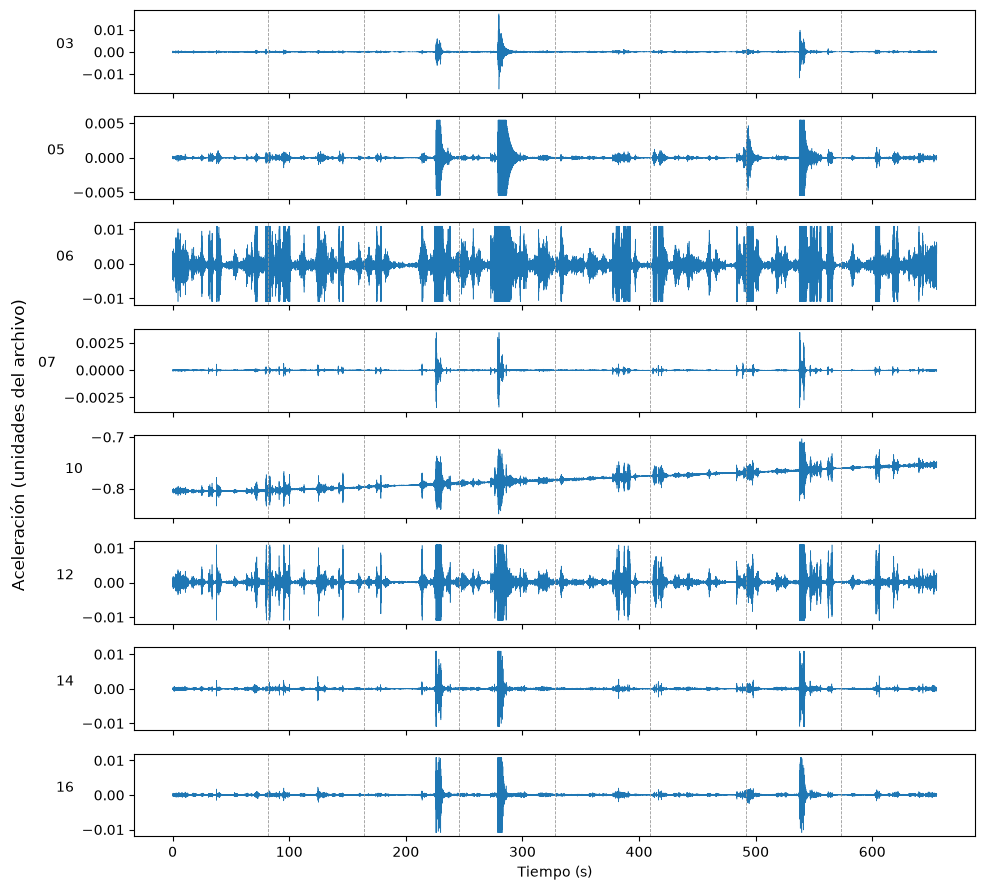

**Figura 1.** Aceleraciones de los 8 canales del EMS en la hora `01C14`. Las líneas grises separan los 8 segmentos de 8192 muestras.

In [7]:
example_code = "01C14"
acc, env_example = load_ems_hour(example_code)
t = np.arange(len(acc)) / FS

stats = acc.agg(["count", "mean", "std", "min", "max"]).T
stats.columns = ["Muestras", "Media", "Desv. estándar", "Mínimo", "Máximo"]
stats["Muestras"] = stats["Muestras"].astype(int)
stats.index.name = "Canal"
t_num += 1
show_table(stats, t_num, f"Estadísticas de los 8 canales de aceleración de la hora `{example_code}`.", precision=6)

fig, axes = plt.subplots(len(acc.columns), 1, figsize=(10, 9), sharex=True)
for ax, ch in zip(axes, acc.columns):
    ax.plot(t, acc[ch], lw=0.4, color="tab:blue")
    ax.set_ylabel(ch, rotation=0, labelpad=12)
    for k in range(1, 8):
        ax.axvline(k * 8192 / FS, color="0.6", lw=0.6, ls="--")
axes[-1].set_xlabel("Tiempo (s)")
fig.supylabel("Aceleración (unidades del archivo)")
fig.tight_layout()
f_num += 1
show_figure(fig, f_num, f"Aceleraciones de los 8 canales del EMS en la hora `{example_code}`. "
            "Las líneas grises separan los 8 segmentos de 8192 muestras.")

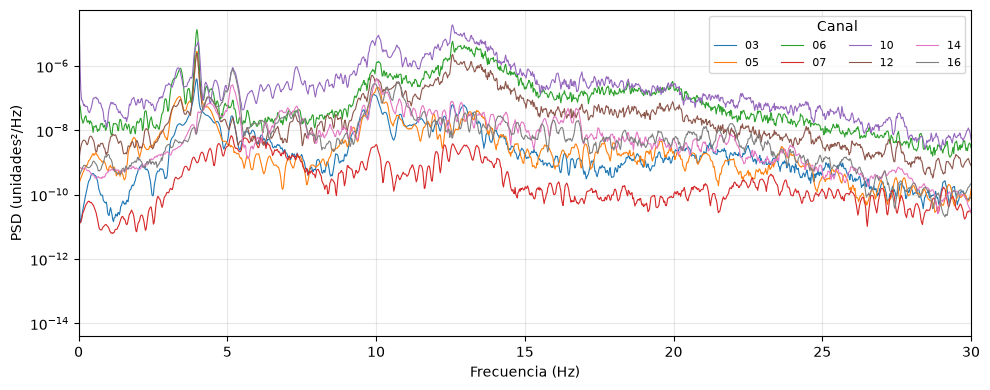

**Figura 2.** Densidad espectral de potencia (Welch, segmentos de 4096 muestras) de los 8 canales en la hora `01C14`.

Most prominent peaks of channel 05 between 2 and 15 Hz (Hz): [ 3.98  6.42  7.37 10.08 11.94 13.38]


In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
for ch in acc.columns:
    f, pxx = psd(acc[ch])
    ax.semilogy(f, pxx, lw=0.8, label=ch)
ax.set_xlim(0, 30)
ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("PSD (unidades²/Hz)")
ax.legend(title="Canal", ncol=4, fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
f_num += 1
show_figure(fig, f_num, f"Densidad espectral de potencia (Welch, segmentos de 4096 muestras) de los 8 canales en la hora `{example_code}`.")

f, pxx = psd(acc["05"])
band = (f > 2) & (f < 15)
peaks, _ = signal.find_peaks(np.log10(pxx[band]), prominence=0.5)
print("Most prominent peaks of channel 05 between 2 and 15 Hz (Hz):", np.round(f[band][peaks], 2))

Lo que se ve en esta hora:
- **Tráfico.** Las ráfagas grandes de la Figura 1 son vehículos que pasan sobre el puente. Entre ellas la señal es mucho menor.
- **Saturación.** En varias ráfagas la señal se recorta en un valor fijo: ±0.0055 en el canal 05 y ±0.0109 en los canales 06, 12, 14 y 16 (Tabla 7). Es el límite del rango de medición. Ese límite cambia de una hora a otra (aparecen también 0.0035, 0.0173, etc.). Los tramos recortados no representan la aceleración real.
- **Canal 10.** Tiene un desplazamiento grande (media de −0.78) y una deriva lenta. En esta hora todavía funciona, pero ver la Tabla 6.
- **Espectro.** Todos los canales muestran un pico claro cerca de 4 Hz, y otros picos entre 5 y 15 Hz. Los picos son frecuencias naturales del puente. Los canales verticales (05, 07, 10, 12) ven sobre todo los modos de flexión vertical; los transversales (14, 16) y longitudinales (03, 06), los modos laterales y longitudinales.

<a id="sec3-4"></a>
### 3.4 Registro de vehículos (`car.aaa`)

El archivo `WWDHHcar.aaa` no aparece en la documentación. Tiene el mismo encabezado que los de aceleración (etiqueta `Carlog`, 65 536 muestras, 0.01 s), pero:
- Solo contiene ceros y unos.
- Trae menos valores que los que declara (unos 64 500 en lugar de 65 536).
- Está en alrededor del 72 % de las horas.

Por el nombre, parece una señal de paso de vehículos sobre el puente (1 = vehículo). Es una hipótesis: no está confirmado en la documentación.

In [9]:
car_label, car_declared, car_dt, car = read_aaa(open_ems_hour("17A08").read("17A08car.aaa"))
print(f"Label: {car_label} | declared samples: {car_declared} | values read: {len(car)} | dt = {car_dt} s")
print(f"Unique values: {np.unique(car)} | fraction of ones: {car.mean():.1%}")
print(f"Hours with car.aaa: {ems['has_car'].mean():.1%} of {len(ems)}")

Label: Carlog | declared samples: 65536 | values read: 64521 | dt = 0.01 s
Unique values: [0. 1.] | fraction of ones: 10.4%
Hours with car.aaa: 72.1% of 5653


<a id="sec3-5"></a>
### 3.5 Variables ambientales (`.env`)

Cada archivo `.env` tiene una fila de encabezado con las etiquetas, 10 filas de lecturas (*scans*, unos 14 s en total) y un pie de texto. Hay dos por hora: PRE y POS.

La Tabla 8 resume el significado de cada etiqueta, según la Tabla 11 de `Z24-EMS-readme.pdf`. Las variables meteorológicas vienen en voltios y hay que convertirlas; las temperaturas ya vienen en °C. Las temperaturas de la estructura se miden en 3 secciones del tablero (`i` = 1, 2, 3; Fig. 39 del readme) y en 9 posiciones de cada sección (Fig. 38).

In [10]:
env_meaning = pd.DataFrame([
    ("WS", "Velocidad del viento", "V", "× 5 → m/s"),
    ("WD", "Dirección del viento", "V", "× 36 → grados"),
    ("AT", "Temperatura del aire", "V", "100·V − 40 → °C"),
    ("R", "Lluvia (sí/no)", "V", "3 V = sí, 1 V = no"),
    ("H", "Humedad relativa", "V", "× 10 → % (ver nota)"),
    ("TE", "Dilatación térmica entre pilas (hilo invar)", "V", "× 5 → mm"),
    ("ADU, ADK", "Giro en la cabeza de la pila Utzenstorf / Koppigen", "V", "conversión perdida"),
    ("TSPU1–3, TSPK1–3", "Temperatura del suelo junto a la pila Utzenstorf / Koppigen, 3 profundidades (0.2, 0.6, 1.0 m)", "°C", "—"),
    ("TSAU1–3, TSAK1–3", "Temperatura del suelo junto al estribo Utzenstorf / Koppigen, 3 profundidades (0.4, 0.8, 1.2 m)", "°C", "—"),
    ("TBC1, TBC2", "Temperatura del aire dentro del cajón", "°C", "—"),
    ("TSWSi, TSWNi", "Temperatura de la vereda sur (Berna) / norte (Zúrich), sección i", "°C", "—"),
    ("TWSi, TWCi, TWNi", "Temperatura del alma sur / central / norte, sección i", "°C", "—"),
    ("TPi", "Temperatura del pavimento, sección i", "°C", "—"),
    ("TDTi, TDSi", "Temperatura de la losa superior: cara superior / inferior, sección i", "°C", "—"),
    ("TSi", "Temperatura de la losa inferior del cajón, sección i", "°C", "—"),
], columns=["Etiqueta", "Significado", "Unidad en el archivo", "Conversión"])

t_num += 1
show_table(env_meaning, t_num, "Variables ambientales del EMS (Tabla 11 de `Z24-EMS-readme.pdf`).", hide_index=True)
print("Columns read from the example file:", env_example.shape[1])
print(list(env_example.columns))

**Tabla 8.** Variables ambientales del EMS (Tabla 11 de `Z24-EMS-readme.pdf`).

Etiqueta,Significado,Unidad en el archivo,Conversión
WS,Velocidad del viento,V,× 5 → m/s
WD,Dirección del viento,V,× 36 → grados
AT,Temperatura del aire,V,100·V − 40 → °C
R,Lluvia (sí/no),V,"3 V = sí, 1 V = no"
H,Humedad relativa,V,× 10 → % (ver nota)
TE,Dilatación térmica entre pilas (hilo invar),V,× 5 → mm
"ADU, ADK",Giro en la cabeza de la pila Utzenstorf / Koppigen,V,conversión perdida
"TSPU1–3, TSPK1–3","Temperatura del suelo junto a la pila Utzenstorf / Koppigen, 3 profundidades (0.2, 0.6, 1.0 m)",°C,—
"TSAU1–3, TSAK1–3","Temperatura del suelo junto al estribo Utzenstorf / Koppigen, 3 profundidades (0.4, 0.8, 1.2 m)",°C,—
"TBC1, TBC2",Temperatura del aire dentro del cajón,°C,—


Columns read from the example file: 53
['WS', 'WD', 'AT', 'R', 'H', 'TE', 'ADU', 'ADK', 'TSPU1', 'TSPU2', 'TSPU3', 'TSAU1', 'TSAU2', 'TSAU3', 'TSPK1', 'TSPK2', 'TSPK3', 'TSAK1', 'TSAK2', 'TSAK3', 'TBC1', 'TBC2', 'TSWS1', 'TSWN1', 'TWS1', 'TWC1', 'TWN1', 'TP1', 'TDT1', 'TDS1', 'TS1', 'TSWS2', 'TSWN2', 'TWS2', 'TWC2', 'TWN2', 'TP2', 'TDT2', 'TDS2', 'TS2', 'TWS3', 'TWN3', 'TWS3_2', 'TWC3', 'TWN3_2', 'TP3', 'TDT3', 'TS3', 'col48', 'col49', 'col50', 'col51', 'col52']


Detalles del formato que hay que tener en cuenta:
- **Encabezado incompleto.** Hay 53 columnas numéricas, pero el encabezado solo tiene 48 etiquetas. Las columnas 48 a 52 quedan sin nombre (`col48`–`col52`).
- **Etiquetas repetidas.** En la sección 3 el encabezado dice `TWS3, TWN3, TWS3, TWC3, TWN3`, cuando según la Tabla 11 debería decir `TSWS3, TSWN3, TWS3, TWC3, TWN3`. Además falta `TDS3`. Así que la asignación de etiquetas a columnas en la sección 3 no es segura. Aquí se renombran las repetidas con un sufijo (`TWS3_2`, `TWN3_2`).
- **Humedad.** Con la conversión de la Tabla 11 (× 10), la humedad saldría entre 4 % y 10 %, lo que no es razonable. Con × 100 queda entre 40 % y 98 %. Es probable que la tabla tenga un error, pero no está confirmado.
- **Valores centinela.** Cuando un sensor no da lectura aparece 3276.7, −242.7 o −244.3. Aquí se tratan como faltantes todos los valores con $|x| \geq 100$.

La Figura 3 muestra, para cada columna, en qué fracción de las horas hay un valor válido.

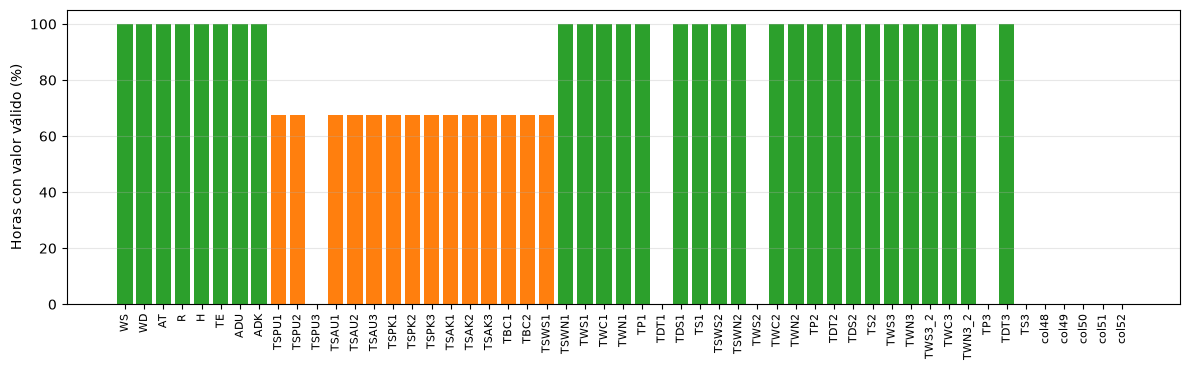

**Figura 3.** Disponibilidad de cada columna ambiental del EMS (promedio PRE de cada hora). Verde: más del 90 % de las horas; naranja: entre 10 % y 90 %; rojo: menos del 10 %.

Columns that never have a valid value: ['TSPU3', 'TDT1', 'TWS2', 'TP3', 'TS3', 'col48', 'col49', 'col50', 'col51', 'col52']
Columns with 10-90 % valid hours: ['TSPU1', 'TSPU2', 'TSAU1', 'TSAU2', 'TSAU3', 'TSPK1', 'TSPK2', 'TSPK3', 'TSAK1', 'TSAK2', 'TSAK3', 'TBC1', 'TBC2', 'TSWS1']


In [11]:
env_cols = [c for c in ems.columns if c not in
            ["archive", "code", "n_files", "channels", "has_car", "has_pre", "has_pos", "start"]
            and not c.startswith(("std_", "mean_"))]
env_values = ems[env_cols].where(ems[env_cols].abs() < SENTINEL_ABS)
valid = env_values.notna().mean()

fig, ax = plt.subplots(figsize=(12, 3.8))
colors = np.where(valid > 0.9, "tab:green", np.where(valid > 0.1, "tab:orange", "tab:red"))
ax.bar(range(len(valid)), valid.values * 100, color=colors)
ax.set_xticks(range(len(valid)), valid.index, rotation=90, fontsize=8)
ax.set_ylabel("Horas con valor válido (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
f_num += 1
show_figure(fig, f_num, "Disponibilidad de cada columna ambiental del EMS (promedio PRE de cada hora). "
            "Verde: más del 90 % de las horas; naranja: entre 10 % y 90 %; rojo: menos del 10 %.")

print("Columns that never have a valid value:", list(valid[valid < 0.01].index))
print("Columns with 10-90 % valid hours:", list(valid[(valid > 0.1) & (valid < 0.9)].index))

In [12]:
wind = env_values[["WS", "WD"]].describe().loc[["mean", "min", "max"]]
wind.index = ["Media", "Mínimo", "Máximo"]
t_num += 1
show_table(wind, t_num, "Valores de las columnas de viento en voltios (promedio PRE de cada hora).", precision=4)

**Tabla 9.** Valores de las columnas de viento en voltios (promedio PRE de cada hora).

,WS,WD
Media,-0.0001,-0.0002
Mínimo,-0.0006,-0.0007
Máximo,0.0002,0.0003


- Las columnas de viento (`WS`, `WD`) están prácticamente en cero todo el tiempo: el anemómetro no parece haber registrado nada útil.
- Las columnas en rojo no tienen ningún dato. Las de suelo y algunas del tablero tienen datos solo en parte del periodo.
- Las temperaturas del tablero en las secciones 1 y 2 y la temperatura del aire (`AT`) son las más completas. Son las que se usan normalmente para estudiar el efecto de la temperatura en las frecuencias.

<a id="sec3-6"></a>
### 3.6 Cobertura en el tiempo

El EMS midió cada hora, pero hubo interrupciones. La Tabla 10 lista los huecos de más de 3 horas y la Figura 4 muestra la temperatura del aire y de la losa inferior, junto con el número de horas medidas cada día.

In [13]:
gap = ems["start"].diff()
gaps = pd.DataFrame({"Última hora antes": ems["start"].shift()[gap > pd.Timedelta("3h")],
                     "Primera hora después": ems["start"][gap > pd.Timedelta("3h")],
                     "Duración": gap[gap > pd.Timedelta("3h")]}).reset_index(drop=True)
t_num += 1
show_table(gaps, t_num, "Interrupciones del EMS de más de 3 horas.", hide_index=True)

n_dup = ems["start"].dt.floor("h").duplicated().sum()
print(f"Hours: {len(ems)} | span: {(ems['start'].max() - ems['start'].min()).days} days | "
      f"duplicated hours: {n_dup} | hours after the first pier lowering: {(ems['start'] >= FIRST_LOWERING).sum()}")

**Tabla 10.** Interrupciones del EMS de más de 3 horas.

Última hora antes,Primera hora después,Duración
1998-01-10 01:00:11,1998-01-12 17:00:12,2 days 16:00:01
1998-01-28 16:00:10,1998-01-30 15:00:11,1 days 23:00:01
1998-02-16 01:00:11,1998-02-16 08:00:14,0 days 07:00:03
1998-03-03 05:00:10,1998-03-03 14:00:13,0 days 09:00:03
1998-03-18 18:00:10,1998-03-21 17:00:12,2 days 23:00:02
1998-04-05 21:00:12,1998-04-09 13:00:13,3 days 16:00:01
1998-04-24 16:00:10,1998-05-28 14:00:10,33 days 22:00:00
1998-06-04 11:00:10,1998-06-15 18:00:10,11 days 07:00:00
1998-06-19 10:00:10,1998-06-19 16:00:10,0 days 06:00:00
1998-07-03 18:00:10,1998-07-06 09:00:10,2 days 15:00:00


Hours: 5653 | span: 303 days | duplicated hours: 2 | hours after the first pier lowering: 674


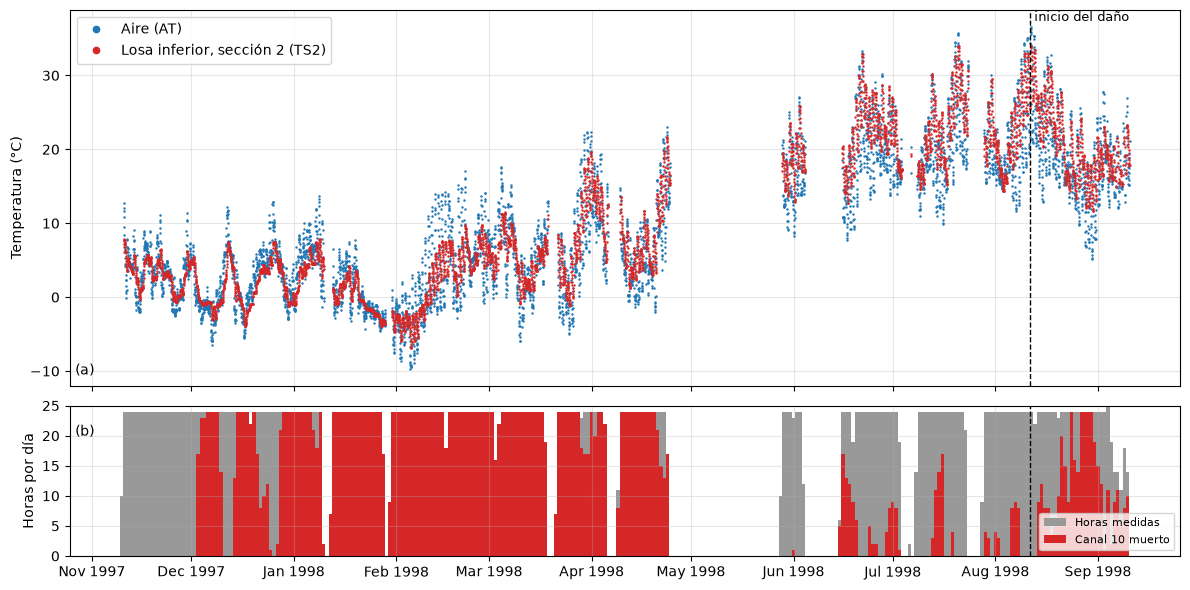

**Figura 4.** (a) Temperatura del aire y de la losa inferior del cajón en cada hora del EMS. (b) Número de horas medidas por día (gris) y, de ellas, horas con el canal 10 muerto (rojo). La línea discontinua marca el primer descenso de la pila (11.08.1998, Tabla 8 del Apéndice F).

In [14]:
air_temp = 100 * env_values["AT"] - 40   # conversion of Table 11 (V -> degC)
per_day = ems.set_index("start").resample("D").size()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [2.5, 1]})
ax1.plot(ems["start"], air_temp, ".", ms=1.5, color="tab:blue", label="Aire (AT)")
ax1.plot(ems["start"], env_values["TS2"], ".", ms=1.5, color="tab:red", label="Losa inferior, sección 2 (TS2)")
ax1.set_ylabel("Temperatura (°C)")
ax1.legend(markerscale=6, loc="upper left")
dead10_per_day = ems.loc[ems["std_10"] < 1e-9].set_index("start").resample("D").size().reindex(per_day.index, fill_value=0)
ax2.bar(per_day.index, per_day.values, width=1, color="0.6", label="Horas medidas")
ax2.bar(dead10_per_day.index, dead10_per_day.values, width=1, color="tab:red", label="Canal 10 muerto")
ax2.legend(fontsize=8, loc="lower right")
ax2.set_ylabel("Horas por día")
ax2.set_ylim(0, 25)
for ax in (ax1, ax2):
    ax.axvline(FIRST_LOWERING, color="k", ls="--", lw=1)
    ax.grid(alpha=0.3)
ax1.text(FIRST_LOWERING, ax1.get_ylim()[1], " inicio del daño", va="top", fontsize=9)
ax1.text(0.005, 0.03, "(a)", transform=ax1.transAxes)
ax2.text(0.005, 0.8, "(b)", transform=ax2.transAxes)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout()
f_num += 1
show_figure(fig, f_num, "(a) Temperatura del aire y de la losa inferior del cajón en cada hora del EMS. "
            "(b) Número de horas medidas por día (gris) y, de ellas, horas con el canal 10 muerto (rojo). "
            "La línea discontinua marca el primer descenso de la pila "
            "(11.08.1998, Tabla 8 del Apéndice F).")

- El EMS cubre un invierno con temperaturas bajo cero y un verano con más de 25 °C. Ese rango es lo que permite estudiar el efecto de la temperatura (por ejemplo, el aumento de rigidez del asfalto cuando se congela, conocido en la literatura del Z24).
- Hay un hueco de 34 días entre fines de abril y fines de mayo de 1998, otro de 11 días en junio y varios más cortos.
- Hay 2 horas repetidas (dos archivos con la misma hora de inicio).
- Las 674 horas posteriores a la línea discontinua corresponden al puente con daño.

---
<a id="sec4"></a>
## 4. Ensayos de daño progresivo (PDT)

<a id="sec4-1"></a>
### 4.1 Organización de los archivos

```
pdt_01-08.zip
├── 01/
│   ├── avt/
│   │   ├── 01setup01.mat ... 01setup09.mat   ← 9 setups del ensayo ambiental
│   │   └── 168'349_701A.DOC                  ← informe del ensayo (Word)
│   └── fvt/
│       ├── 01setup01.mat ... 01setup09.mat   ← 9 setups del ensayo forzado
│       └── 168'349_701F.DOC
├── 02/ ... 07/
└── 08/
    ├── avt.zip   ← el escenario 08 viene en ZIP anidados
    └── fvt.zip
pdt_09_17.zip
├── 09/ ... 16/
└── 17/
    ├── avt/
    └── FVT/      ← en mayúsculas
```

Diferencias respecto del patrón general:
- El escenario 08 viene dos veces: en las carpetas `08/avt`, `08/fvt` y en dos ZIP anidados (`08/avt.zip`, `08/fvt.zip`). Los `.mat` son idénticos (mismo CRC), así que aquí se usan los de las carpetas.
- Los ensayos `06/avt`, `17/avt` y `17/FVT` traen además subcarpetas `01/` a `09/` con un `.aaa` por canal (el formato original del CD, Apéndice K). Se comprobó que contienen los mismos valores que el `.mat`, así que son una copia.
- Algunos ensayos no traen el `.DOC` (03, `05/fvt`, `15/fvt`).
- Los `.DOC` explican las convenciones de dirección y los problemas de cableado. Sin embargo, la mayoría son una copia de la plantilla del escenario 01: el título y la fecha no corresponden al escenario. Solo unos pocos tienen texto propio (`02/fvt`, `04/avt`, `04/fvt`, `12/avt`). Por eso el nombre de cada escenario se toma de la literatura (4.2).

In [15]:
pdt = pdt_index()
per_test = pdt.pivot_table(index="scenario", columns="test", values="setup", aggfunc="count").fillna(0).astype(int)
per_test.columns = [f"Setups {c}" for c in per_test.columns]
per_test["Archivo"] = pdt.groupby("scenario")["archive"].first()
per_test.index.name = "Escenario"

t_num += 1
show_table(per_test.T, t_num, "Número de archivos `.mat` (setups) por escenario y tipo de ensayo.")
print(f"{len(pdt)} .mat files in total")

**Tabla 11.** Número de archivos `.mat` (setups) por escenario y tipo de ensayo.

Escenario,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
Setups AVT,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
Setups FVT,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
Archivo,pdt_01-08.zip,pdt_01-08.zip,pdt_01-08.zip,pdt_01-08.zip,pdt_01-08.zip,pdt_01-08.zip,pdt_01-08.zip,pdt_01-08.zip,pdt_09_17.zip,pdt_09_17.zip,pdt_09_17.zip,pdt_09_17.zip,pdt_09_17.zip,pdt_09_17.zip,pdt_09_17.zip,pdt_09_17.zip,pdt_09_17.zip


306 .mat files in total


<a id="sec4-2"></a>
### 4.2 Escenarios de daño

Los 17 escenarios se aplicaron en orden, uno sobre otro (el daño se acumula). La Tabla 12 los resume.

**Fuente:** la lista viene de la literatura del Z24 (por ejemplo, Maeck y De Roeck, 2003; Reynders y De Roeck, 2009), no de los archivos de `datos/`. Dentro de `datos/` solo la confirman en parte los `.DOC` de los escenarios 04 ("40 mm Settlement") y 12 ("Failure of concrete hinges at abutment piers") y la Tabla 8 del Apéndice F (descensos de la pila de 20 a 95 mm).

In [16]:
scenarios = pd.DataFrame([
    (1, "Primera medición de referencia", "Referencia"),
    (2, "Segunda referencia, con el sistema de descenso de pila instalado", "Referencia"),
    (3, "Descenso de la pila Koppigen, 20 mm", "Asentamiento de pila"),
    (4, "Descenso de la pila, 40 mm", "Asentamiento de pila"),
    (5, "Descenso de la pila, 80 mm", "Asentamiento de pila"),
    (6, "Descenso de la pila, 95 mm", "Asentamiento de pila"),
    (7, "Pila levantada de nuevo; inclinación de la fundación", "Asentamiento de pila"),
    (8, "Tercera medición de referencia", "Referencia"),
    (9, "Desprendimiento de hormigón en la losa inferior, 12 m²", "Daño del hormigón"),
    (10, "Desprendimiento de hormigón en la losa inferior, 24 m²", "Daño del hormigón"),
    (11, "Deslizamiento de tierra en un estribo", "Apoyos"),
    (12, "Falla de las rótulas de hormigón en los estribos", "Apoyos"),
    (13, "Falla de 2 anclajes de pretensado", "Pretensado"),
    (14, "Falla de 4 anclajes de pretensado", "Pretensado"),
    (15, "Rotura de 2 de 16 cables de pretensado", "Pretensado"),
    (16, "Rotura de 4 de 16 cables de pretensado", "Pretensado"),
    (17, "Rotura de 6 de 16 cables de pretensado", "Pretensado"),
], columns=["Escenario", "Descripción", "Tipo"])

t_num += 1
show_table(scenarios, t_num, "Escenarios de daño progresivo del Z24 (fuente: literatura).", hide_index=True)

**Tabla 12.** Escenarios de daño progresivo del Z24 (fuente: literatura).

Escenario,Descripción,Tipo
1,Primera medición de referencia,Referencia
2,"Segunda referencia, con el sistema de descenso de pila instalado",Referencia
3,"Descenso de la pila Koppigen, 20 mm",Asentamiento de pila
4,"Descenso de la pila, 40 mm",Asentamiento de pila
5,"Descenso de la pila, 80 mm",Asentamiento de pila
6,"Descenso de la pila, 95 mm",Asentamiento de pila
7,Pila levantada de nuevo; inclinación de la fundación,Asentamiento de pila
8,Tercera medición de referencia,Referencia
9,"Desprendimiento de hormigón en la losa inferior, 12 m²",Daño del hormigón
10,"Desprendimiento de hormigón en la losa inferior, 24 m²",Daño del hormigón


<a id="sec4-3"></a>
### 4.3 Setups, malla de medición y canales

**La malla** (Apéndice L de `C11-Appendices.pdf`):
- **Tablero:** tres líneas longitudinales de puntos. Línea 1 (puntos 99–143) en el lado sur (Berna), línea 2 (199–243) en el eje y línea 3 (299–343) en el lado norte (Zúrich). Los dos últimos dígitos indican la posición a lo largo del puente (de −1 a 43); la pila Utzenstorf está cerca de la posición 10.
- **Pilas:** 8 puntos en cada una, en 4 niveles y 2 columnas: 411–442 en la pila Utzenstorf y 511–542 en la pila Koppigen.
- **Referencias:** R1, R2 y R3, en la línea del lado sur, fijas en todos los setups.

**Nombre de canal** = punto + dirección. Por ejemplo, `202T` es el punto 202 en dirección transversal.

**Direcciones** (de los `.DOC`):
- Tablero: L positivo hacia Koppigen, V hacia arriba, T hacia Berna.
- Pila Koppigen: los sensores están en el plano de la pila, girados respecto del tablero. **L es vertical** (hacia arriba), V es horizontal hacia Koppigen y T hacia Zúrich.
- Pila Utzenstorf: L es vertical (hacia arriba), V horizontal hacia Utzenstorf y T hacia Berna.

**Setups:** en el AVT el setup 1 está en el extremo Utzenstorf y el 9 en el extremo Koppigen. En el FVT el orden es el inverso. Cada setup mide 5 posiciones de las tres líneas del tablero, más dos puntos de una pila (salvo el setup 5) y las 5 señales de referencia. Las pilas no siguen el orden del tablero: en el AVT los setups 1 a 4 miden la pila Koppigen y los setups 6 a 9, la pila Utzenstorf.

La Tabla 13 muestra los canales de cada setup del AVT del escenario 01, leídos de los archivos.

In [17]:
def deck_line_position(point):
    # Deck points 99-143, 199-243, 299-343 -> (line 1-3, position -1..43 along the bridge)
    return (point + 1) // 100, (point + 1) % 100 - 1


def channel_summary(df):
    labels = list(df.columns)
    points = [c for c in labels if c[0].isdigit()]
    deck = [c for c in points if int(c[:-1]) < 400]
    piers = [c for c in points if int(c[:-1]) >= 400]
    positions = [deck_line_position(int(c[:-1]))[1] for c in deck]
    return {"canales": len(labels), "tablero": len(deck), "pilas": len(piers),
            "referencias": sum(c.startswith("R") for c in labels), "fuerza": sum(c.startswith("DP") for c in labels),
            "posiciones del tablero": f"{min(positions)} a {max(positions)}",
            "puntos de pila": ", ".join(sorted({c[:-1] for c in piers}))}

setup_labels = {s: load_pdt(1, "AVT", s, pdt) for s in range(1, 10)}
setups_01 = pd.DataFrame({s: channel_summary(df) for s, df in setup_labels.items()}).T
setups_01.index.name = "Setup"

t_num += 1
show_table(setups_01, t_num, "Canales de cada setup del AVT del escenario 01.")
print("Setup 1 channels:", " ".join(setup_labels[1].columns))

**Tabla 13.** Canales de cada setup del AVT del escenario 01.

,canales,tablero,pilas,referencias,fuerza,posiciones del tablero,puntos de pila
Setup,,,,,,,
1,33,22,6,5,0,-1 a 3,"511, 512"
2,33,22,6,5,0,4 a 8,"521, 522"
3,33,22,6,5,0,9 a 13,"531, 532"
4,33,22,6,5,0,14 a 18,"541, 542"
5,27,22,0,5,0,19 a 23,
6,33,22,6,5,0,24 a 28,"411, 412"
7,31,20,6,5,0,29 a 33,"421, 422"
8,33,22,6,5,0,34 a 38,"431, 432"
9,33,22,6,5,0,39 a 43,"441, 442"


Setup 1 channels: 99V 100V 101V 102V 103V 199L 199T 199V 200T 200V 201T 201V 202T 202V 203L 203T 203V 299V 300V 301V 302V 303V 511L 511T 511V 512L 512T 512V R1V R2L R2T R2V R3V


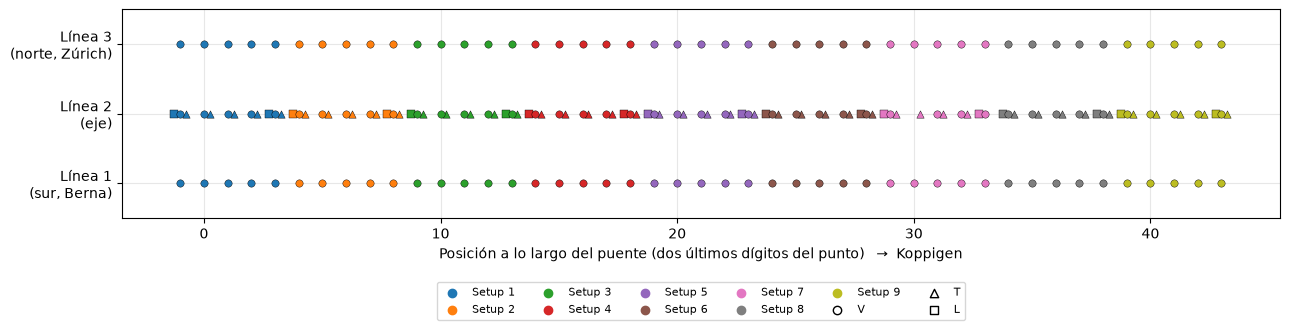

**Figura 5.** Puntos del tablero medidos en cada setup del AVT del escenario 01, leídos de `labelshulp`. Círculo: vertical (V); triángulo: transversal (T); cuadrado: longitudinal (L). No se muestran los puntos de las pilas ni las referencias.

In [18]:
direction_marker = {"V": "o", "T": "^", "L": "s"}
direction_shift = {"V": 0.0, "T": 0.25, "L": -0.25}   # small shift so the three directions do not overlap
cmap = plt.get_cmap("tab10")

fig, ax = plt.subplots(figsize=(13, 3.6))
for s, df in setup_labels.items():
    for lab in df.columns:
        if not lab[0].isdigit() or int(lab[:-1]) >= 400:
            continue
        line, position = deck_line_position(int(lab[:-1]))
        direction = lab[-1]
        ax.scatter(position + direction_shift[direction], line, marker=direction_marker[direction],
                   color=cmap(s - 1), s=28, edgecolor="k", linewidth=0.3, zorder=3)
for s in range(1, 10):
    ax.scatter([], [], marker="o", color=cmap(s - 1), label=f"Setup {s}")
for d, m in direction_marker.items():
    ax.scatter([], [], marker=m, color="w", edgecolor="k", label=d)
ax.set_yticks([1, 2, 3], ["Línea 1\n(sur, Berna)", "Línea 2\n(eje)", "Línea 3\n(norte, Zúrich)"])
ax.set_ylim(0.5, 3.5)
ax.set_xlabel("Posición a lo largo del puente (dos últimos dígitos del punto)   →  Koppigen")
ax.legend(ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.28))
ax.grid(alpha=0.3)
fig.tight_layout()
f_num += 1
show_figure(fig, f_num, "Puntos del tablero medidos en cada setup del AVT del escenario 01, leídos de `labelshulp`. "
            "Círculo: vertical (V); triángulo: transversal (T); cuadrado: longitudinal (L). "
            "No se muestran los puntos de las pilas ni las referencias.")

- Las tres líneas tienen sensores verticales en todas las posiciones. Esto permite ver flexión y torsión del tablero.
- La línea 2 (eje) tiene además sensores transversales en todas las posiciones y longitudinales en los extremos de cada setup.
- Faltan algunos canales en ciertos setups (por ejemplo, el setup 7 tiene 31 canales en lugar de 33). Los `.DOC` explican parte de esas pérdidas (errores de cableado).

<a id="sec4-4"></a>
### 4.4 Archivos `.mat` y ejemplo

Cada `.mat` contiene (según `readme.txt`):
- `data`: matriz de muestras × canales, a 100 Hz.
- `labelshulp`: el nombre de cada columna.

Las señales se adquirieron igual que en el EMS: 8 segmentos de 8192 muestras. Los `.DOC` indican además:
- Los canales `DP1V` y `DP2V` (solo en el FVT) son las fuerzas de los dos excitadores. DP1 está en el punto de la referencia R2 y DP2 en el de R1.
- En el escenario 02, la fuerza `DP2` debe multiplicarse por 6.25.
- En el AVT del escenario 04 casi todas las señales tienen deriva del cero; recomiendan quitar una tendencia ajustada antes de analizarlas.

Ejemplo: el canal de referencia `R2V` en el setup 1 del escenario 01, en el AVT y en el FVT.

AVT: (65530, 33) | FVT: (65530, 34)
Force channels in FVT setup 1: ['DP2V']
Std of R2V: AVT 1.17e-04 | FVT 3.79e-03


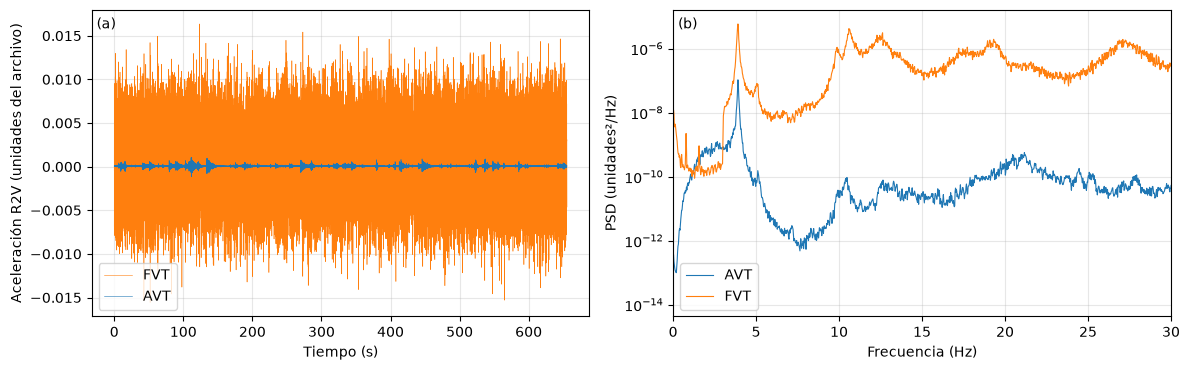

**Figura 6.** Canal de referencia `R2V`, setup 1 del escenario 01. (a) Serie de tiempo en el AVT y en el FVT. (b) Densidad espectral de potencia (Welch, segmentos de 4096 muestras).

In [19]:
avt = load_pdt(1, "AVT", 1, pdt)
fvt = load_pdt(1, "FVT", 1, pdt)
print("AVT:", avt.shape, "| FVT:", fvt.shape)
print("Force channels in FVT setup 1:", [c for c in fvt.columns if c.startswith("DP")])
print(f"Std of R2V: AVT {avt['R2V'].std():.2e} | FVT {fvt['R2V'].std():.2e}")

colors = {"AVT": "tab:blue", "FVT": "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
t_avt = np.arange(len(avt)) / FS
axes[0].plot(t_avt, fvt["R2V"], lw=0.4, color=colors["FVT"], label="FVT")
axes[0].plot(t_avt, avt["R2V"], lw=0.4, color=colors["AVT"], label="AVT")
axes[0].set_xlabel("Tiempo (s)")
axes[0].set_ylabel("Aceleración R2V (unidades del archivo)")
axes[0].legend()
for name, df in [("AVT", avt), ("FVT", fvt)]:
    f, pxx = psd(df["R2V"])
    axes[1].semilogy(f, pxx, lw=0.8, color=colors[name], label=name)
axes[1].set_xlim(0, 30)
axes[1].set_xlabel("Frecuencia (Hz)")
axes[1].set_ylabel("PSD (unidades²/Hz)")
axes[1].legend()
for ax, tag in zip(axes, ["(a)", "(b)"]):
    ax.grid(alpha=0.3)
    ax.text(0.01, 0.94, tag, transform=ax.transAxes)
fig.tight_layout()
f_num += 1
show_figure(fig, f_num, "Canal de referencia `R2V`, setup 1 del escenario 01. (a) Serie de tiempo en el AVT y en el FVT. "
            "(b) Densidad espectral de potencia (Welch, segmentos de 4096 muestras).")

- En el FVT la desviación estándar de la respuesta es unas 30 veces mayor que en el AVT y el espectro está varios órdenes de magnitud más alto en toda la banda excitada.
- El pico principal, cerca de 4 Hz, aparece en ambos ensayos. El FVT hace visibles más picos (cerca de 5, 10, 12 y 19 Hz) que en el AVT quedan tapados por el ruido.
- Los setups 1 del AVT y del FVT no miden los mismos puntos (el orden de los setups es inverso). Por eso se comparan con un canal de referencia, que es el mismo en ambos.

<a id="sec4-5"></a>
### 4.5 Inventario completo

La celda siguiente lee el tamaño y los nombres de canal de los 306 archivos `.mat` (unos 15 s; no carga las señales).

In [20]:
rows = []
for row in pdt.itertuples():
    raw = io.BytesIO(read_pdt_bytes(row))
    shape = dict((name, shp) for name, shp, _ in sio.whosmat(raw))["data"]
    raw.seek(0)
    labels = [str(lab).strip() for lab in sio.loadmat(raw, variable_names=["labelshulp"])["labelshulp"]]
    rows.append(dict(scenario=row.scenario, test=row.test, setup=row.setup, n_samples=shape[0],
                     n_channels=shape[1], n_force=sum(lab.startswith("DP") for lab in labels),
                     labels=" ".join(labels)))
pdt_inv = pd.DataFrame(rows)

per_scenario = pdt_inv.groupby(["scenario", "test"]).agg(
    **{"setups": ("setup", "count"),
       "muestras": ("n_samples", lambda s: "/".join(map(str, sorted(s.unique())))),
       "canales mín": ("n_channels", "min"), "canales máx": ("n_channels", "max"),
       "canales total": ("n_channels", "sum"),
       "fuerza": ("n_force", lambda s: f"{s.min()}–{s.max()}")})
per_scenario.index.names = ["Escenario", "Ensayo"]
t_num += 1
show_table(per_scenario.unstack("Ensayo").swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False),
           t_num, "Inventario de los PDT por escenario y ensayo: setups, muestras por canal, canales por setup "
           "(mínimo, máximo y total) y número de canales de fuerza por setup.")

**Tabla 14.** Inventario de los PDT por escenario y ensayo: setups, muestras por canal, canales por setup (mínimo, máximo y total) y número de canales de fuerza por setup.

In [21]:
unique_points = (pdt_inv.query("test == 'AVT'")["labels"].str.split().explode().loc[lambda s: s.str[0].str.isdigit()]
                 .str[:-1].nunique())
print(f"Total .mat files: {len(pdt_inv)} | channels x setups: {pdt_inv['n_channels'].sum()} | "
      f"distinct measured points (AVT): {unique_points}")
print("Samples per record:", pdt_inv["n_samples"].value_counts().to_dict(),
      f"-> {pdt_inv['n_samples'].min() / FS:.1f} to {pdt_inv['n_samples'].max() / FS:.1f} s")

Total .mat files: 306 | channels x setups: 10189 | distinct measured points (AVT): 151
Samples per record: {65536: 268, 65530: 36, 65026: 1, 65410: 1} -> 650.3 to 655.4 s


- Todos los escenarios tienen 9 setups de AVT y 9 de FVT: 306 registros en total.
- Casi todos los registros tienen 65 536 muestras por canal (655 s a 100 Hz). Los escenarios 01 y 02 tienen 65 530, y dos registros del AVT (escenarios 03 y 07) son algo más cortos.
- En el FVT de los escenarios 01 y 02, algunos setups tienen solo una de las dos señales de fuerza.
- El número de canales varía un poco entre setups y escenarios por canales perdidos. Antes de comparar escenarios hay que buscar los canales por nombre (`labelshulp`), no por número de columna.

---
<a id="sec5"></a>
## 5. Resumen: con qué información contamos

**Monitoreo continuo (EMS):**
- Unas 5650 horas entre el 10.11.1997 y el 10.09.1998, con huecos (el más largo, de abril a mayo de 1998).
- 8 acelerómetros (en el tablero: 4 verticales, 2 transversales y 1 longitudinal; en una pila: 1 longitudinal), 655 s a 100 Hz por hora, en 8 segmentos.
- Variables ambientales cada hora: temperatura del aire, temperaturas del tablero en 3 secciones, temperaturas del suelo, humedad, lluvia y dilatación térmica.
- 674 horas después del inicio del daño (11.08.1998).
- El canal 10 está muerto en el 60 % de las horas, y varios canales se saturan cuando pasan vehículos pesados.
- Sirve para: estudiar el efecto de la temperatura en las frecuencias, seguir las frecuencias en el tiempo y probar métodos de detección de daño con datos reales (hay periodo sano y periodo dañado).

**Ensayos de daño progresivo (PDT):**
- 17 escenarios (3 de referencia y 14 de daño acumulado).
- Por escenario, un AVT y un FVT, cada uno con 9 setups de 27 a 35 canales, a 100 Hz y 655 s.
- Malla densa: 3 líneas en el tablero y 2 pilas, con 5 canales de referencia comunes a todos los setups. El FVT añade las fuerzas de 2 excitadores.
- Sirve para: identificar frecuencias, amortiguamientos y formas modales completas en cada escenario, y comparar cómo cambian con el daño.

**Precauciones al usar los datos:**
- Las unidades de la aceleración no están documentadas.
- Los 655 s de cada registro son 8 segmentos que pueden tener pausas entre ellos.
- EMS: hay que filtrar las horas con canales planos (sobre todo el canal 10) y tener en cuenta los tramos saturados.
- El escenario 08 de los PDT está duplicado (carpetas y ZIP anidados).
- En los `.env` hay valores centinela, columnas sin datos, viento en cero y etiquetas dudosas en la sección 3. La conversión de la humedad parece estar mal en la tabla.
- `car.aaa` no está documentado.
- Los `.DOC` de los PDT son en su mayoría copia de una plantilla; la lista de escenarios viene de la literatura.
- Faltan algunos canales en ciertos setups: hay que buscar los canales por nombre.